The goal of this notebook is to do some post hoc filtering of fishy cells/clusters that might have been missed in our previous QC steps.

The idea is to get a few metrics that could be used for a simple sanity check to spot the most fishy clusters, and then remove those clusters from the atlas.



In [1]:
from pathlib import Path
import tempfile
import os 
from dotenv import dotenv_values

import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from sklearn.cluster import DBSCAN

from hm3d_utils.utils import write_clean_h5ad
from project_utils import FileTracker

sc.set_figure_params(frameon=False, figsize=(10,10), transparent=True)

In [2]:
CONFIG = dotenv_values("config.env") 
DATADIR = Path(CONFIG['DATADIR'])

CLUSTERING_DIR = DATADIR / "5_clustering"
MODELDIR = CLUSTERING_DIR / 'all_control'
DATASETS_DIR = MODELDIR / "datasets"

ADATA_IN_FP = DATASETS_DIR / f'control_clustered.h5ad'
ADATA_OUT_FP = DATASETS_DIR / f'control_clustered_qc.h5ad'

MARKERS_FP = CLUSTERING_DIR / "HypoMap3D_marker_genes.csv"
PRELIM_ANNOT = CLUSTERING_DIR / "prelim_v0.6_pre_posthoc_qc.csv"

CELL_HISTORY = DATADIR / "qc_log.csv" #QC log

tracker = FileTracker(log_file=DATADIR/'tracked_files.toml')

In [3]:
adata = sc.read_h5ad(ADATA_IN_FP) 

In [4]:
adata

AnnData object with n_obs × n_vars = 920995 × 56939
    obs: 'CellID', 'Dataset', 'Sample', 'total_counts', 'n_genes', 'pct_mito', 'Author', 'Source', 'Data_source_link', 'GEO', 'Publication_Link', 'Suspension', 'Technology', 'Author_Sex_harmonized', 'Strain', 'Diet', 'Treatment', 'Age', 'Mean_age_in_weeks', 'IsControl', 'cluster_id_label', 'supertype_id_label', 'subclass_id_label', 'class_id_label', 'C66_named', 'C185_named', 'C286_named', 'C465_named', 'ABC_class_propagated', 'ABC_class_confidence', 'to_be_removed', 'IsNeuronal', 'major_features', 'major_features_propagated', 'major_features_confidence', 'ABC_supertype_propagated', 'ABC_supertype_confidence', 'ABC_subclass_propagated', 'ABC_subclass_confidence', 'ABC_cluster_propagated', 'ABC_cluster_confidence', 'L1', 'L2', 'L3', 'L4', 'L5'
    var: 'gene_ids', 'IsMouseTF', 'IsHumanTFOrtholog', 'IsSourceGene', 'IsTargetGene', 'IsHvgExcludedGene', 'IsAnnotationExcludedGene', 'IsPriorityGene', 'IsTopGene', 'IsHvg'
    uns: 'neighbors'

In [5]:
adata.layers["raw"] = adata.X.copy() 
sc.pp.normalize_total(adata, target_sum=10_000)
sc.pp.log1p(adata)

In [6]:
markers = pd.read_csv(MARKERS_FP)

In [7]:
prelim = pd.read_csv(PRELIM_ANNOT)
prelim = prelim.loc[:, ["L4", "L4_prelim"]].drop_duplicates().set_index("L4").to_dict()["L4_prelim"]
#prelim

# Obtaining metrics

The following metrics were considered:

- biggest_sample_ratio (bsr): The ratio of cells within a cluster belonging to the biggest sample within that cluster. Clusters dominated by single samples may indicate clusters that are comparatively less robust than clusters found at somewhat equal ratios of multiple samples. 
- n_unique_samples: The number of unique samples within a cluster. Lower numbers indicate clusters that are either rare or not robust. 
- mean_total_counts, mean_n_genes: the average counts/detected genes for cells of a cluster will directly help to identify lower quality clusters.
- n_dbscan_clusters, n_outliers: By DBSCANning the UMAP, it is possible to identify clusters with cells scattered across the UMAP, possibly indicating low quality cells/doublets whose nearest neighbors belong to a multitude of clusters.


In [ ]:
# DBSCAN params
eps = 1.0
min_samples = 10

# Get the relevant columns from obs
cluster_sample = adata.obs[['L4', 'Sample', 'total_counts', 'n_genes']].copy()

# Count cells per cluster per sample
counts = cluster_sample.groupby(['L4', 'Sample']).size().reset_index(name='cell_count')

# Mean counts and genes per cluster
qc_stats = cluster_sample.groupby('L4').agg(
    mean_total_counts=('total_counts', 'mean'),
    mean_n_genes=('n_genes', 'mean')
)

# Get the name of the dominant sample
dominant_sample = (counts.sort_values('cell_count', ascending=False)
                         .groupby('L4')
                         .first()['Sample']
                         .rename('dominant_sample'))

# For each cluster: get total cells, max sample count and number of unique samples
sample_stats = counts.groupby('L4').agg(
    cluster_size=('cell_count', 'sum'),
    max_sample_count=('cell_count', 'max'),
)

# Get number of unique samples directly from original data
n_unique_samples = cluster_sample.groupby('L4')['Sample'].nunique().rename('n_unique_samples')


dbscan_results = []

for cl in adata.obs.L4.unique():
    in_cluster = adata.obs.L4 == cl
    umap_coords = adata.obsm['X_umap'][in_cluster]
    
    # Run DBSCAN
    dbscan = DBSCAN(eps=eps, min_samples=min_samples)
    labels = dbscan.fit_predict(umap_coords)
    
    n_cells = len(labels)
    n_dbscan_clusters = len(set(labels)) - (1 if -1 in labels else 0)  # exclude outlier label -1
    n_outliers = np.sum(labels == -1)
    
    dbscan_results.append({
        'L4': cl,
        'n_dbscan_clusters': n_dbscan_clusters,
        'n_outliers': n_outliers,
    })

dbscan_df = pd.DataFrame(dbscan_results).set_index("L4")

# Combine all stats (all indexed by L4)
result_df = pd.concat([qc_stats, dominant_sample, sample_stats, n_unique_samples, dbscan_df], axis=1).reset_index()

# Calculate dominance ratio and drop intermediate column
result_df['biggest_sample_ratio'] = result_df['max_sample_count'] / result_df['cluster_size']
result_df = result_df.drop(columns='max_sample_count')


/tmp/ipykernel_3314946/798258141.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  counts = cluster_sample.groupby(['L4', 'Sample']).size().reset_index(name='cell_count')
/tmp/ipykernel_3314946/798258141.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  qc_stats = cluster_sample.groupby('L4').agg(
/tmp/ipykernel_3314946/798258141.py:19: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby('L4')
/tmp/ipykernel_3314

In the next cell, a preliminary cluster annotation is mapped in as to get a rough idea about what kind of cells a cluster might be referring to. 
The annotation is from a previous version, in which cells had been clustered, spatially mapped and annotated.

In [ ]:
result_df["L4_prelim"] = result_df.L4.map(prelim)

In [ ]:
result_df.to_csv(MODELDIR / "metrics" / "L4_qc_metrics.csv", index=False)

In [ ]:
#result_df=pd.read_csv(MODELDIR / "metrics" / "L4_qc_metrics.csv")

### Let's flag the most extreme clusters for each metric and plot them

In [9]:
p = 1  # percentile threshold
# hard coded threshold for dbscan clusters 
dbscan_threshold = 3

n_result_df = result_df.loc[~result_df.L4.str.contains("NN"), :]

# Low percentile flags
low_percentile_cols = ['mean_total_counts', 'mean_n_genes','n_unique_samples'
    ]
for col in low_percentile_cols:
    threshold = n_result_df[col].quantile(p / 100)
    print(col, threshold)
    n_result_df[f'flag_low_{col}'] = (n_result_df[col] <= threshold).astype(int)

# High percentile flags
high_percentile_cols = ['n_outliers', 'biggest_sample_ratio']
for col in high_percentile_cols:
    threshold = n_result_df[col].quantile(1 - p / 100)
    print(col, threshold)
    n_result_df[f'flag_high_{col}'] = (n_result_df[col] >= threshold).astype(int)


n_result_df[f'flag_high_dbscan_clusters'] = (n_result_df['n_dbscan_clusters'] >= dbscan_threshold).astype(int)

# Summary flag: how many flags does each cluster have?
flag_cols = [c for c in n_result_df.columns if c.startswith('flag_')]
n_result_df['n_flags'] = n_result_df[flag_cols].sum(axis=1)

mean_total_counts 4890.042305764411
mean_n_genes 2281.750969364392
n_unique_samples 26.72
n_outliers 25.139999999999986
biggest_sample_ratio 0.30913844629886106


/tmp/ipykernel_3834350/1273367281.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  n_result_df[f'flag_low_{col}'] = (n_result_df[col] <= threshold).astype(int)
/tmp/ipykernel_3834350/1273367281.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  n_result_df[f'flag_low_{col}'] = (n_result_df[col] <= threshold).astype(int)
/tmp/ipykernel_3834350/1273367281.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value ins

In [10]:
def plot_umap_flag(adata, flag_col, ax=None, true_color="red", false_color="lightgrey", s_false=20, s_true=200, title=None):
    """
    Plots UMAP of adata, highlighting cells where flag_col is True on top of cells where it is False.

    Parameters
    ----------
    adata : AnnData
    flag_col : str
        Column in adata.obs containing a boolean flag.
    ax : matplotlib axis, optional
        If None, a new figure and axis will be created.
    true_color : str
        Color for flagged (True) cells.
    false_color : str
        Color for non-flagged (False) cells.
    s_false : int
        Marker size for False cells.
    s_true : int
        Marker size for True cells.
    title : str, optional
        Plot title. Defaults to flag_col name.
    """

    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 5))

    is_flagged = adata.obs[flag_col].values.astype(bool)
    n_true = is_flagged.sum()
    n_false = (~is_flagged).sum()

    # Background: False cells
    ax.scatter(
        adata.obsm['X_umap'][~is_flagged, 0],
        adata.obsm['X_umap'][~is_flagged, 1],
        c=false_color, s=s_false, rasterized=True, label=f"False (n={n_false})"
    )

    # Foreground: True cells
    ax.scatter(
        adata.obsm['X_umap'][is_flagged, 0],
        adata.obsm['X_umap'][is_flagged, 1],
        c=true_color, s=s_true, rasterized=True, label=f"True (n={n_true})"
    )

    ax.set_title(title if title else flag_col)
    ax.set_xlabel('UMAP1')
    ax.set_ylabel('UMAP2')
    ax.axis('off')
    ax.legend(markerscale=2, frameon=False, fontsize=8)

    return ax

In [11]:
def plot_clusters_gridspec_flag(clusters_to_plot, title, result_df, adata, color_by="Sample", plot_prelim_name=False):

    # Define flag columns and short display names
    flag_columns = {
        'flag_low_mean_total_counts': 'low_counts',
        'flag_low_mean_n_genes': 'low_genes',
        'flag_low_n_unique_samples': 'low_samples',
        'flag_high_n_outliers': 'high_outliers',
        'flag_high_biggest_sample_ratio': 'high_bsr',
        'flag_high_dbscan_clusters': 'high_dbscan'
    }

    n_cols = 3
    n_rows = int(np.ceil(len(clusters_to_plot) / n_cols))

    fig = plt.figure(figsize=(6 * n_cols, 5 * n_rows))
    gs = fig.add_gridspec(n_rows, n_cols, hspace=0.4, wspace=0.3)

    for idx, cl in enumerate(clusters_to_plot):
        cluster_row = result_df.loc[result_df.L4 == cl]

        mean_counts = cluster_row["mean_total_counts"].iloc[0].round(1)
        mean_genes = cluster_row["mean_n_genes"].iloc[0].round(1)
        cluster_size = cluster_row["cluster_size"].iloc[0]
        bsr = cluster_row["biggest_sample_ratio"].iloc[0].round(2)
        n_unique_samples = cluster_row["n_unique_samples"].iloc[0]
        n_dbscan_clusters = cluster_row["n_dbscan_clusters"].iloc[0]
        n_outliers = cluster_row["n_outliers"].iloc[0]
        if plot_prelim_name:
            prelim_name = cluster_row["L4_prelim"].iloc[0]

        # Get active flags
        active_flags = [
            short_name
            for col, short_name in flag_columns.items()
            if (col in cluster_row.columns) & (cluster_row[col].iloc[0] == 1)
        ]
        flags_str = ", ".join(active_flags) if active_flags else "none"

        # Boolean mask
        in_cluster = adata.obs.L4 == cl

        # Get samples and assign colors
        samples_in_cluster = adata.obs.loc[in_cluster, color_by]
        unique_samples = samples_in_cluster.unique()
        colors = cm.tab20(np.linspace(0, 1, len(unique_samples)))
        sample_color_map = {sample: colors[i] for i, sample in enumerate(unique_samples)}

        row, col = divmod(idx, n_cols)
        ax = fig.add_subplot(gs[row, col])

        # Plot all cells in light grey as background
        ax.scatter(
            adata.obsm['X_umap'][~in_cluster, 0],
            adata.obsm['X_umap'][~in_cluster, 1],
            c='lightgrey', s=5, rasterized=True
        )

        # Plot cluster cells colored by sample on top
        for sample, color in sample_color_map.items():
            is_sample = (samples_in_cluster == sample).values
            ax.scatter(
                adata.obsm['X_umap'][in_cluster][is_sample, 0],
                adata.obsm['X_umap'][in_cluster][is_sample, 1],
                c=[color], s=10, rasterized=True, label=sample
            )

        ax.set_title(
            f"{prelim_name if plot_prelim_name else cl}\nn={cluster_size} | n_samples={n_unique_samples} | bsr={bsr}\n"
            f"counts={mean_counts} | genes={mean_genes}\n"
            f"n_dbscan={n_dbscan_clusters} | n_outliers={n_outliers}\n"
            f"flags: {flags_str}",
            fontsize=8
        )
        ax.set_xlabel('UMAP1')
        ax.set_ylabel('UMAP2')
        ax.axis('off')

    # Hide any unused subplots
    for idx in range(len(clusters_to_plot), n_rows * n_cols):
        row, col = divmod(idx, n_cols)
        fig.add_subplot(gs[row, col]).axis('off')

    plt.suptitle(title + f" colored by {color_by}", fontsize=20)
    plt.show()

In [12]:
n_result_df.loc[:, [c for c in n_result_df.columns if "flag" in c]].sum(axis=0)

flag_low_mean_total_counts         7
flag_low_mean_n_genes              7
flag_low_n_unique_samples          7
flag_high_n_outliers               7
flag_high_biggest_sample_ratio     7
flag_high_dbscan_clusters         13
n_flags                           48
dtype: int64

In [13]:
[c for c in n_result_df.columns if "flag" in c]

['flag_low_mean_total_counts',
 'flag_low_mean_n_genes',
 'flag_low_n_unique_samples',
 'flag_high_n_outliers',
 'flag_high_biggest_sample_ratio',
 'flag_high_dbscan_clusters',
 'n_flags']

In [14]:
flagged = sorted(n_result_df[n_result_df.n_flags>0].L4.to_list())

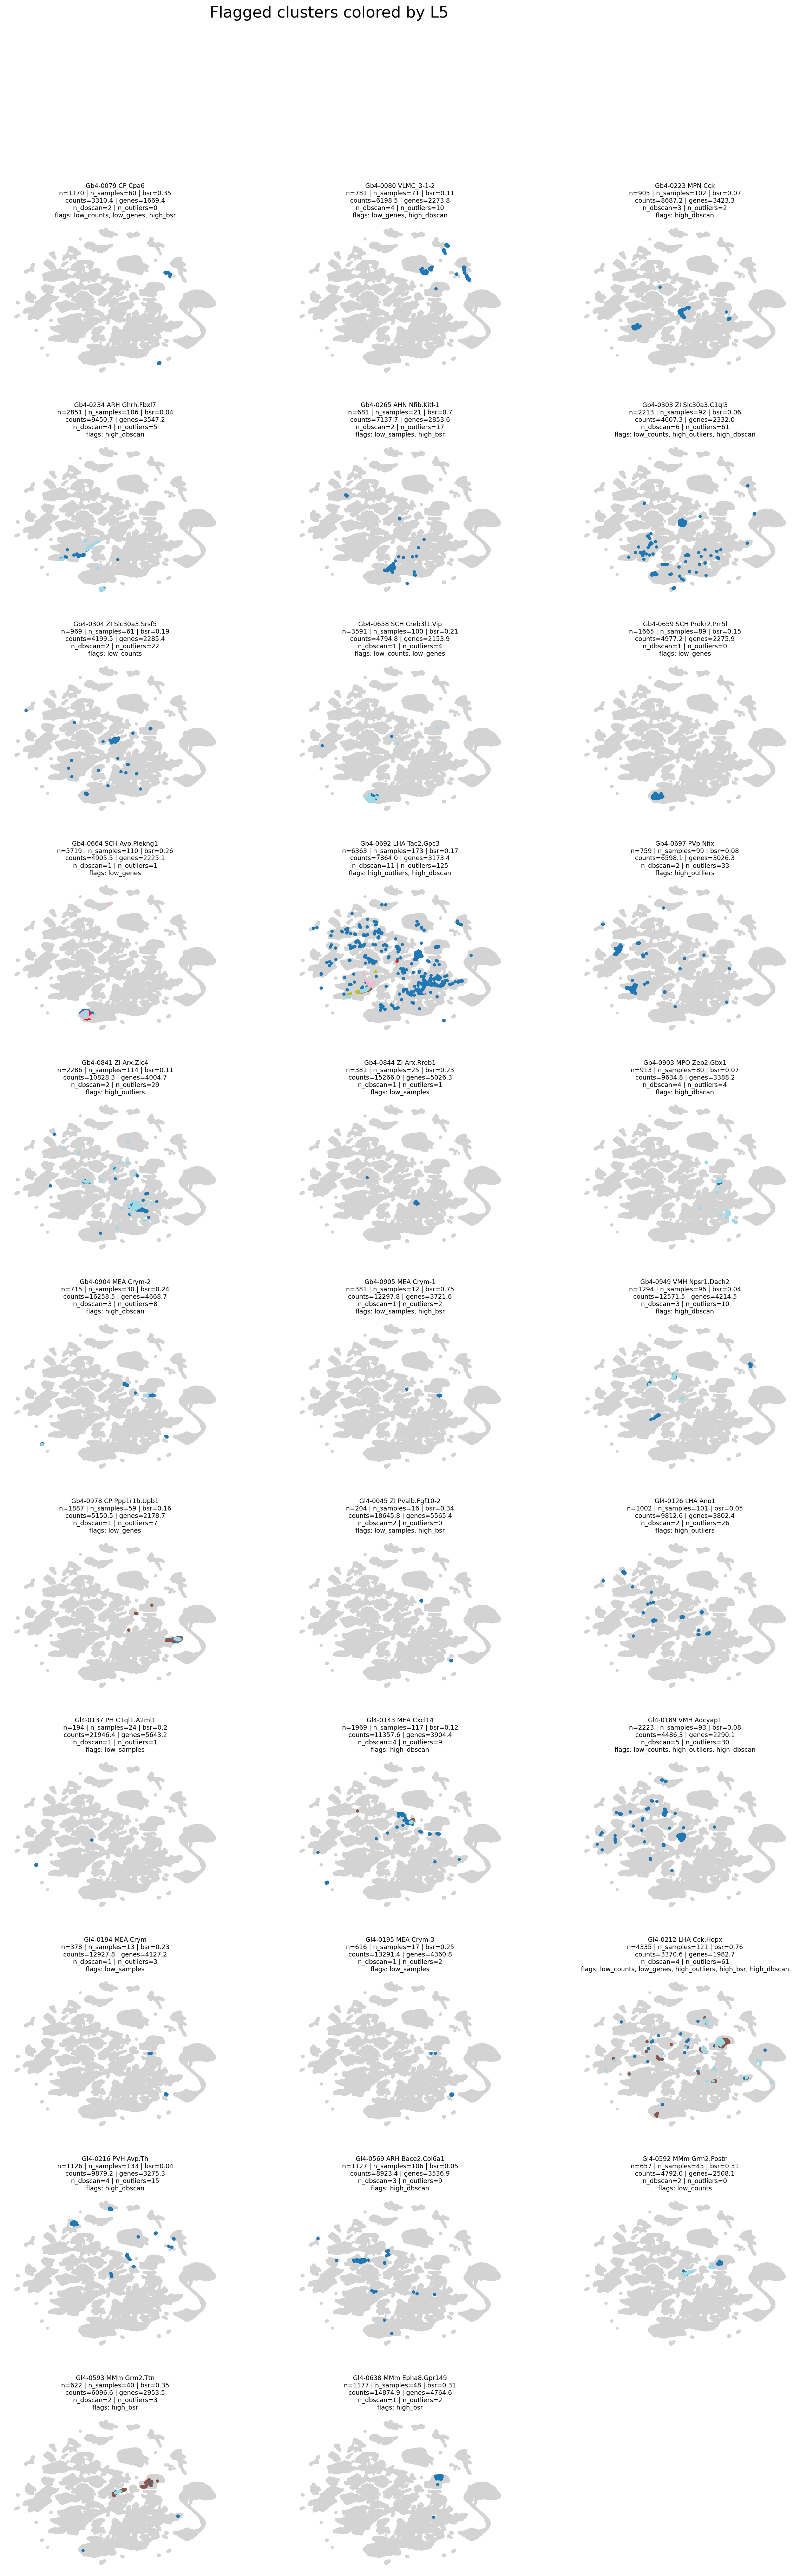

In [15]:
plot_clusters_gridspec_flag(flagged, 'Flagged clusters', n_result_df, adata, color_by="L5", plot_prelim_name=True)

Next, the above flagged clusters were investigated in more detail.

For the sake of the brevity of this notebook, the outcome of the analyses for most of the clusteres is provided in summary below.

Critically, to understand some of the justifications, please take a look at the below UMAP of L1. Specifically, note the region in the middle of the UMAP in which GABAergic, glutamatergic as well as NN cells are located. As evidenced from our flagging, that region is a region in which low-quality cells/clusters seem to be located preferrably. Hence, many clusters being flagged as low quality and residing in that region were removed. 

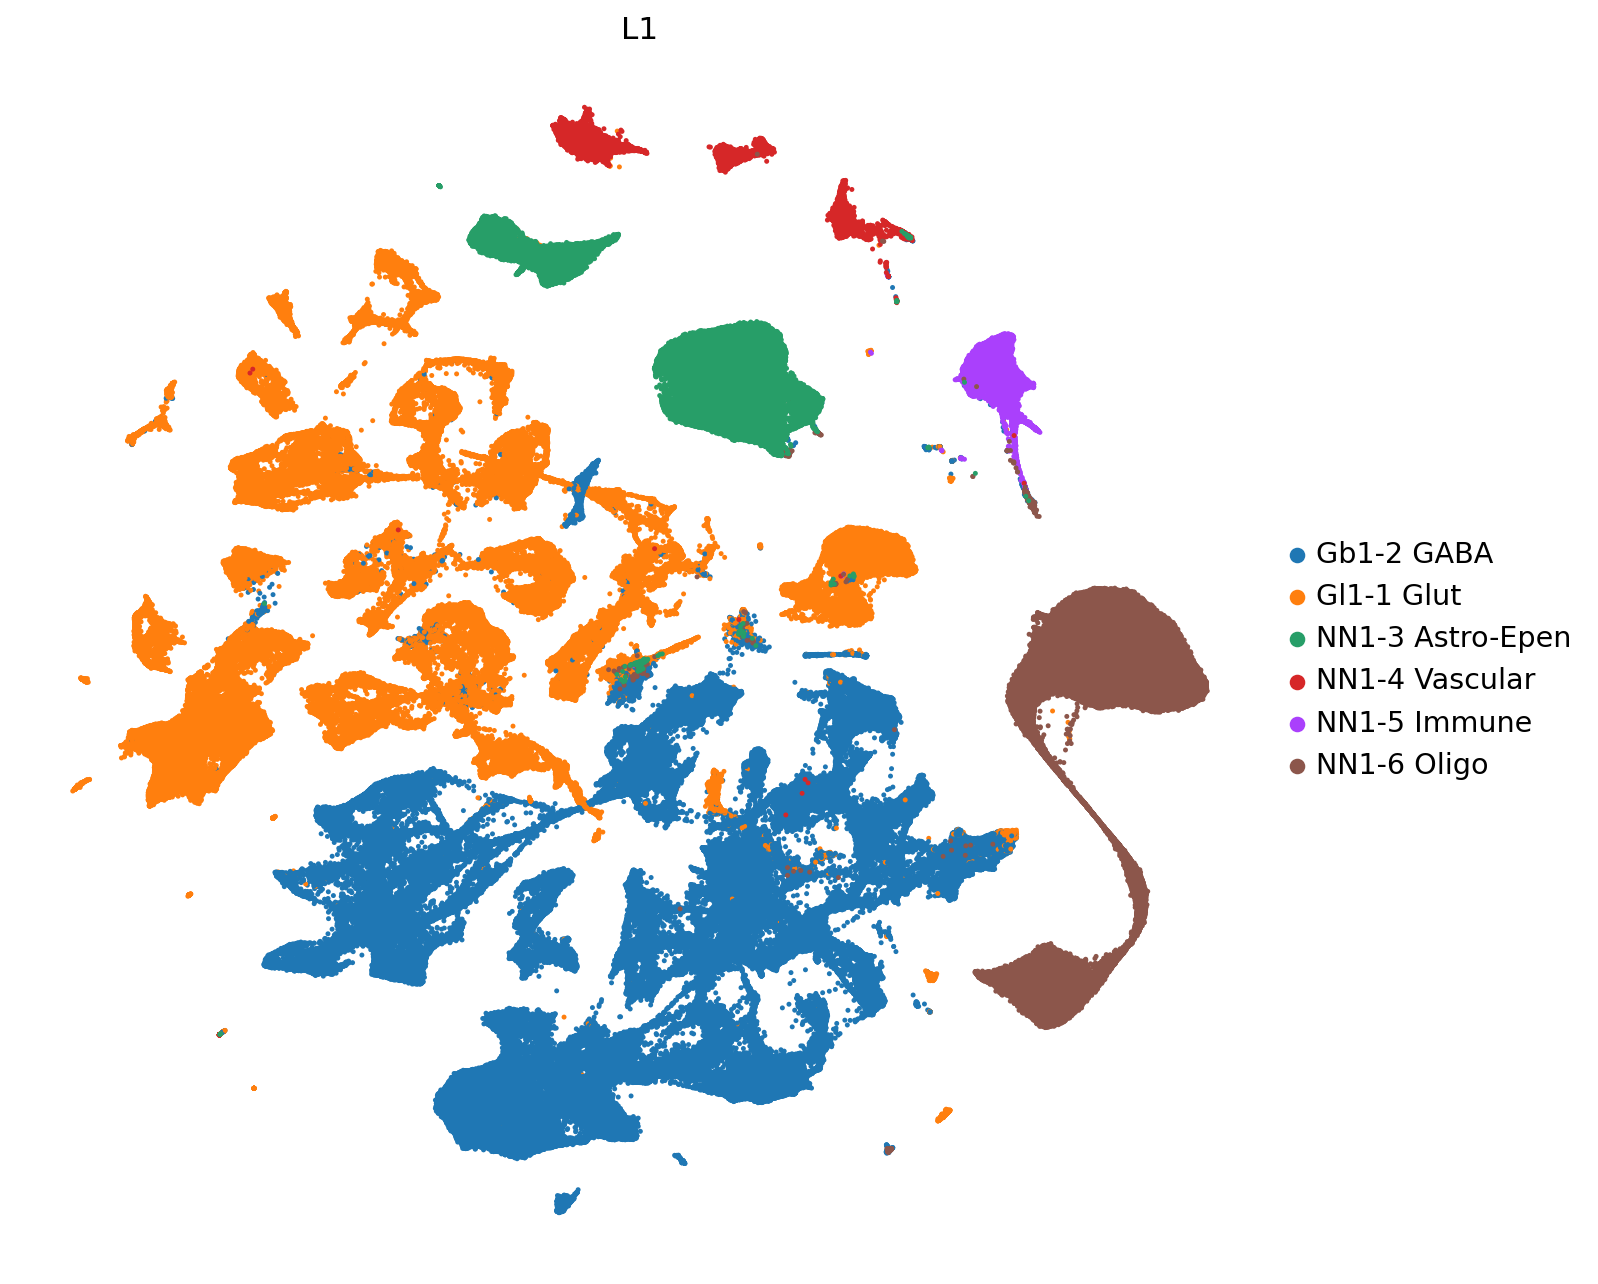

In [16]:
sc.pl.umap(adata, color="L1", s=20)

Furthermore, during the analysis, it came to our attention that there are clusters expressing Slc17a7, which is usually not expressed in hypothalamic cells. Hence, high Slc17a7 expression was used as a criterium to remove clusters as likely non-hypothalamic.

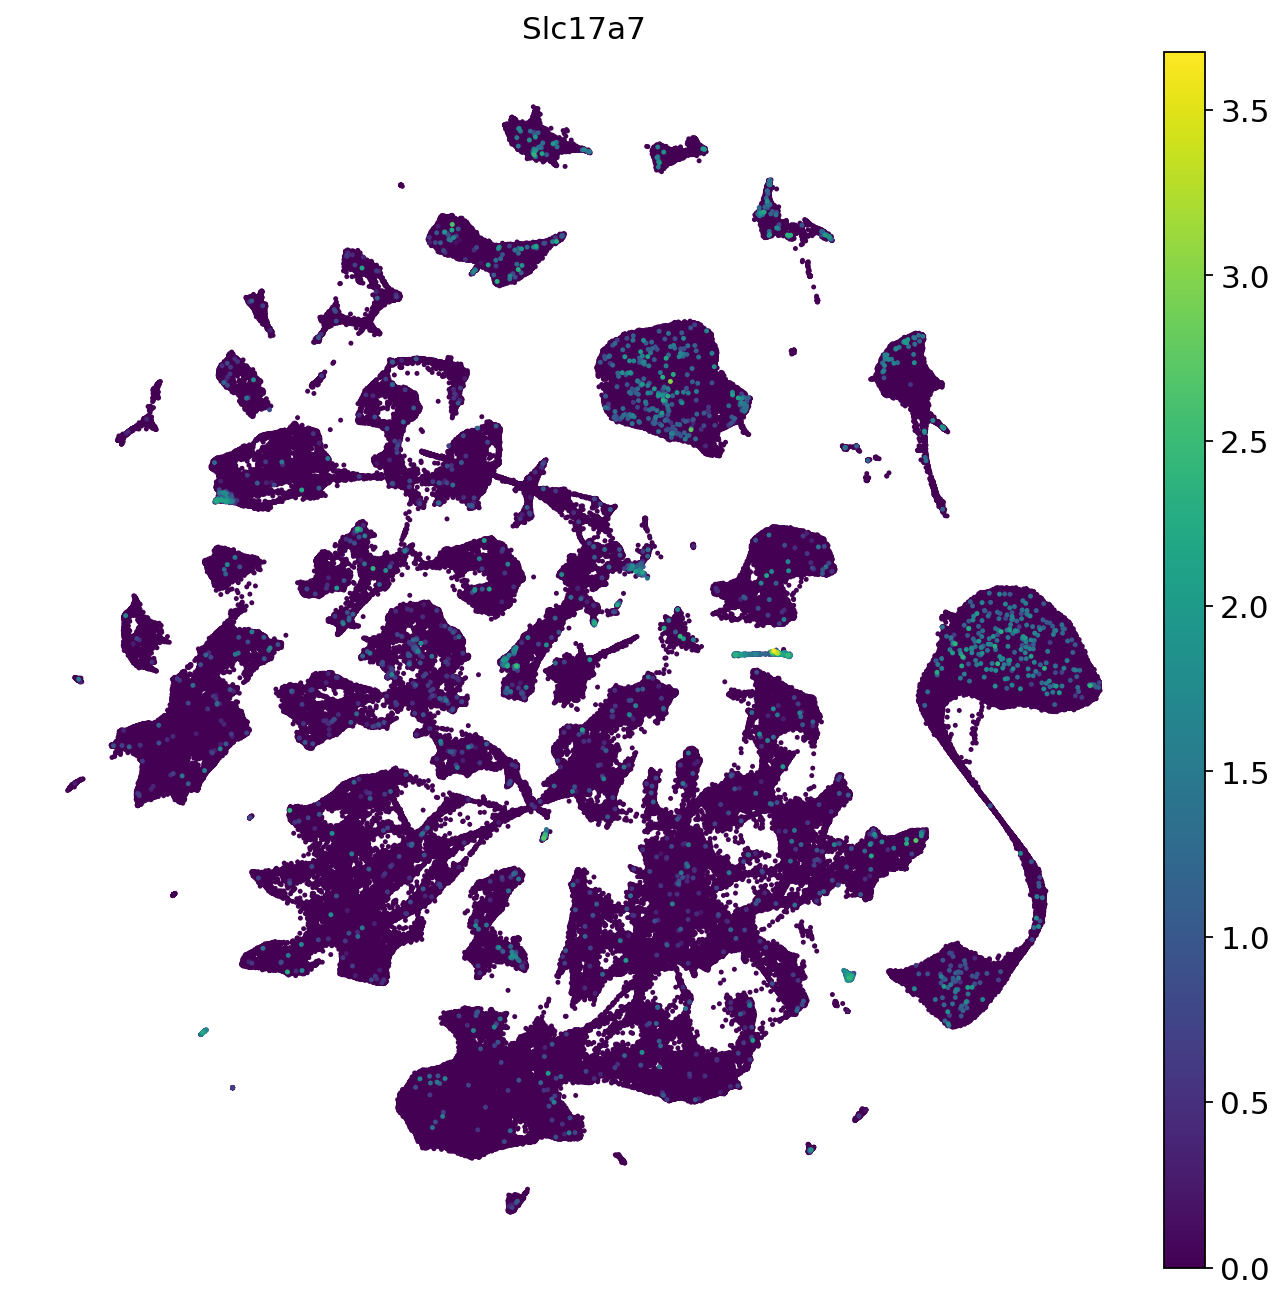

In [17]:
sc.pl.umap(adata, color="Slc17a7", s=20)

The decisions made for each of the flagged clusters:

- Gb4-0079: Removed because of low quality and high dominance of a single sample
- Gb4-0080: Removed because cells rather seem to doublets from non-neuronal clusters rather than neurons
- Gb4-0223: Kept, no reason found for why split in UMAP might indicate low quality
- Gb4-0234: Kept, all valid Ghrh neurons
- Gb4-0265: Removed due to being dominated by a single sample
- Gb4-0303 & Gb4-0304: Removed due to low quality flag and low quality UMAP region
- Gb4-0658 & Gb4-0659 & Gb4-0664: Kept; low quality flags may not indicate actual low quality but rather specifics of the datasets from which the SCH cells are derived from
- Gb4-0692: Removed for unspecific UMAP location and low quality cells 
- Gb4-0697: Kept, these are legit PVp Nfix Tbx3 neurons
- Gb4-0841: Kept, no good reason apart from UMAP noise found
- Gb4-0844: Kept, 25 samples is okay.
- Gb4-0903: Kept, spatial noise in UMAP location alone is not a sufficient reason to remove cluster
- Gb4-0904 & Gb4-0905: Flags + Slc17a7
- Gb4-0949: Removed for immune cell proportion. Likely doublets.
- Gb4-0978: Keep, genes are not too bad, no other reason for exclusion found
- Gl4-0045: Removed for low quality and cell count
- Gl4-0126: Kept, legit LHA Ano1/Otx1 neurons
- Gl4-0137: Removed: markers En2, Pitx3 and Th for this clusters only strongly found in midbrain VTA dopa neurons in ABC data --> probably non-HY
- Gl4-0143: Removed after analysis of L5 subclusters: Gl5-1089 marker Ptpn14 is only in other non-HY clusters --> likely non-HY; Gl5-1090 contains multiple clusters including Slc17a7+ & Gng8+/Dmrt2+ positive cells --> likely non-HY; Gl5-1091 only 2 samples and very few cells, Casr+ --> likely non-HY
- Gl4-0189: Removed for low quality 
- Gl4-0194 & Gl4-0195: Removed for flags and Slc17a7
- Gl4-0212 & Gl4-0216: see below
- Gl4-0569: Kept, spatial noise in UMAP location alone is not a sufficient reason to remove cluster
- Gl4-0592 & Gl4-0593: Removed for low quality
- Gl4-0638: Kept, bsr=0.31 was not a deal breaker given there were 48 samples in that cluster



In [18]:
clusters_to_remove = [
    "Gb4-0079", "Gb4-0080", 
    "Gb4-0265", "Gb4-0303", "Gb4-0304",
    "Gb4-0692", "Gb4-0904", "Gb4-0905","Gb4-0949",
    "Gl4-0045", "Gl4-0137", "Gl4-0148", "Gl4-0189", "Gl4-0194", "Gl4-0195",
    "Gl4-0592", "Gl4-0593" 

]
len(clusters_to_remove)

17

### Investigating Gl4-0212

Considering the plots above, for this cluster many cells fell into the low-quality region.

However, there were also many cells that seemed legit, hence the cells outside of the legit region were removed.

In [19]:
adata.obs["Is_Gl4-0212"] = adata.obs.L4 == "Gl4-0212"

In [20]:
#plt.hist2d(adata[adata.obs["Is_Gl4-0212"]].obsm["X_umap"][:, 0], adata[adata.obs["Is_Gl4-0212"]].obsm["X_umap"][:, 1], bins=50)

In [21]:
adata.obs["Is_Gl4-0212_to_remove"] = (adata.obs["Is_Gl4-0212"]) & (adata.obsm["X_umap"][:, 0] < 5)

gl40212_to_remove = list(adata[adata.obs["Is_Gl4-0212_to_remove"]].obs_names)

<Axes: title={'center': 'Is_Gl4-0212_to_remove'}, xlabel='UMAP1', ylabel='UMAP2'>

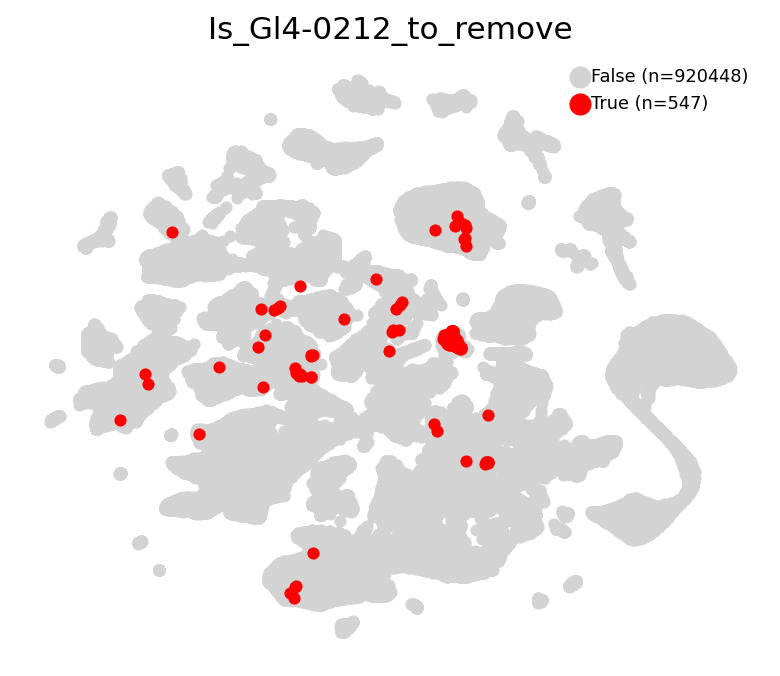

In [22]:
plot_umap_flag(adata, flag_col="Is_Gl4-0212_to_remove", ax=None, true_color="red", false_color="lightgrey", s_false=20, s_true=20, title=None)

### Investigating Gl4-0216

Again, some cells of the cluster were in low-quality/NN regions of the UMAP, so those particular. cells were removed from the cluster

In [23]:
adata.obs["Is_Gl4-0216"] = adata.obs.L4 == "Gl4-0216"

In [24]:
#sc.pl.umap(adata, color=["Avp", "Th"], s=20)

In [25]:
#plt.hist2d(adata[adata.obs["Is_Gl4-0216"]].obsm["X_umap"][:, 0], adata[adata.obs["Is_Gl4-0216"]].obsm["X_umap"][:, 1], bins=50)

In [26]:
adata.obs["Is_Gl4-0216_to_remove"] = (adata.obs["Is_Gl4-0216"]) & (adata.obsm["X_umap"][:, 0] > -4)

gl40216_to_remove = list(adata[adata.obs["Is_Gl4-0216_to_remove"]].obs_names)

<Axes: title={'center': 'Is_Gl4-0216_to_remove'}, xlabel='UMAP1', ylabel='UMAP2'>

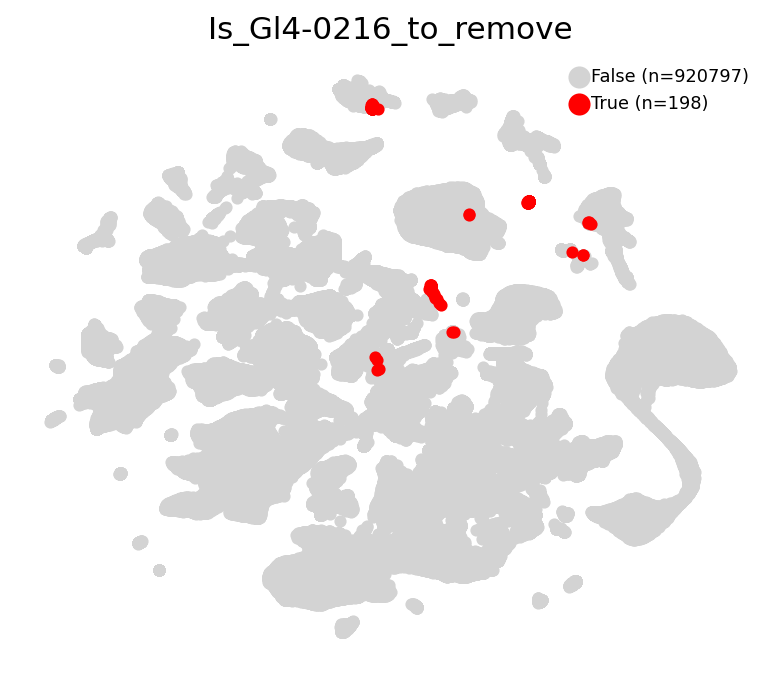

In [27]:
plot_umap_flag(adata, flag_col="Is_Gl4-0216_to_remove", ax=None, true_color="red", false_color="lightgrey", s_false=20, s_true=20, title=None)

### Looking into Gl4-0629

Looking at L1 UMAP, it is suspicious that it is partly in Glut as well as GABA territory.

In [28]:
for cl in ["Gl4-0629",]:
    adata.obs[f"Is_{cl}"] = adata.obs.L4 == cl

for cl in ['Gl5-1207', 'Gl5-1206']: #L5 subclusters of the above
    adata.obs[f"Is_{cl}"] = adata.obs.L5 == cl

<Axes: title={'center': 'Is_Gl4-0629'}, xlabel='UMAP1', ylabel='UMAP2'>

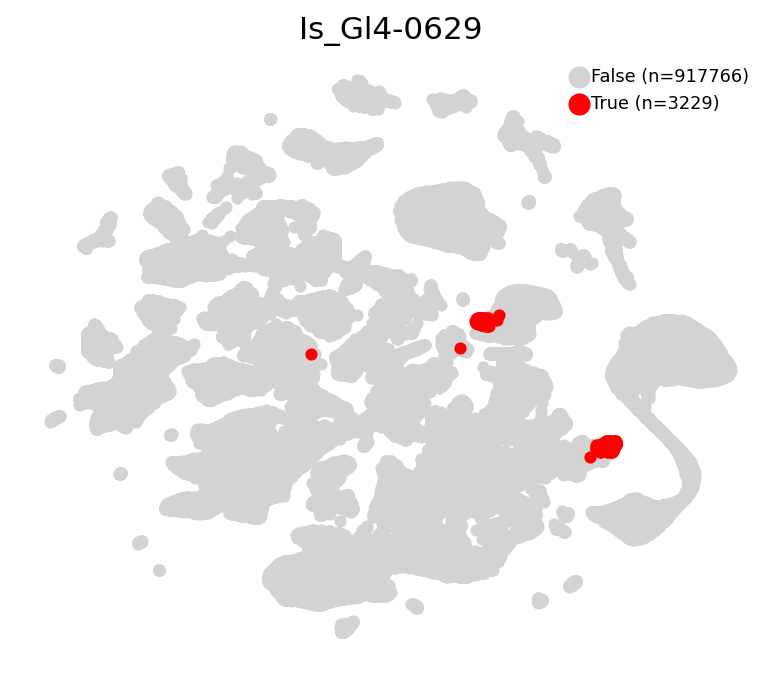

In [29]:
plot_umap_flag(adata, flag_col="Is_Gl4-0629", ax=None, true_color="red", false_color="lightgrey", s_false=20, s_true=20, title=None)

In [30]:
#plt.hist2d(adata[adata.obs["Is_Gl4-0629"]].obsm["X_umap"][:, 0], adata[adata.obs["Is_Gl4-0629"]].obsm["X_umap"][:, 1], bins=50)

In [31]:
adata.obs["Is_Gl4-0629_top"] = (adata.obs["Is_Gl4-0629"]) & (adata.obsm["X_umap"][:, 1] > -2)
adata.obs["Is_Gl4-0629_bottom"] = (adata.obs["Is_Gl4-0629"]) & (adata.obsm["X_umap"][:, 1] <= -2)
adata.obs["Gl4-0629_part"] = np.nan 
adata.obs.loc[adata.obs["Is_Gl4-0629_bottom"], "Gl4-0629_part"] = "bottom"
adata.obs.loc[adata.obs["Is_Gl4-0629_top"], "Gl4-0629_part"] = "top"

/tmp/ipykernel_3834350/1233543061.py:4: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'bottom' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  adata.obs.loc[adata.obs["Is_Gl4-0629_bottom"], "Gl4-0629_part"] = "bottom"


In [32]:
for cl in [c for c in adata.obs.columns if "Is_" in c]:
    print(cl, adata.obs[cl].sum())

Is_Gl4-0212 4335
Is_Gl4-0212_to_remove 547
Is_Gl4-0216 1126
Is_Gl4-0216_to_remove 198
Is_Gl4-0629 3229
Is_Gl5-1207 2722
Is_Gl5-1206 507
Is_Gl4-0629_top 1804
Is_Gl4-0629_bottom 1425


In [33]:
sum((adata.obs["Is_Gl4-0629_top"]) & (adata.obs["Is_Gl5-1206"])), sum((adata.obs["Is_Gl4-0629_top"]) & (adata.obs["Is_Gl5-1207"]))

(507, 1297)

When looking at the markers of the L5 cluster that is only in the top part (Gl5-1206), it was noted that those genes are also expressed in the cells from the L5 cluster that is also in the bottom part of the UMAP (Gl5-1207), so the cells of Gl5-1207 present in the top part seem to be cells that are similar to Gl5-1206 cells, so they should not be removed.

/REDACTED-path/HypoMap3D/.venv/lib/python3.11/site-packages/anndata/_core/anndata.py:1208: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


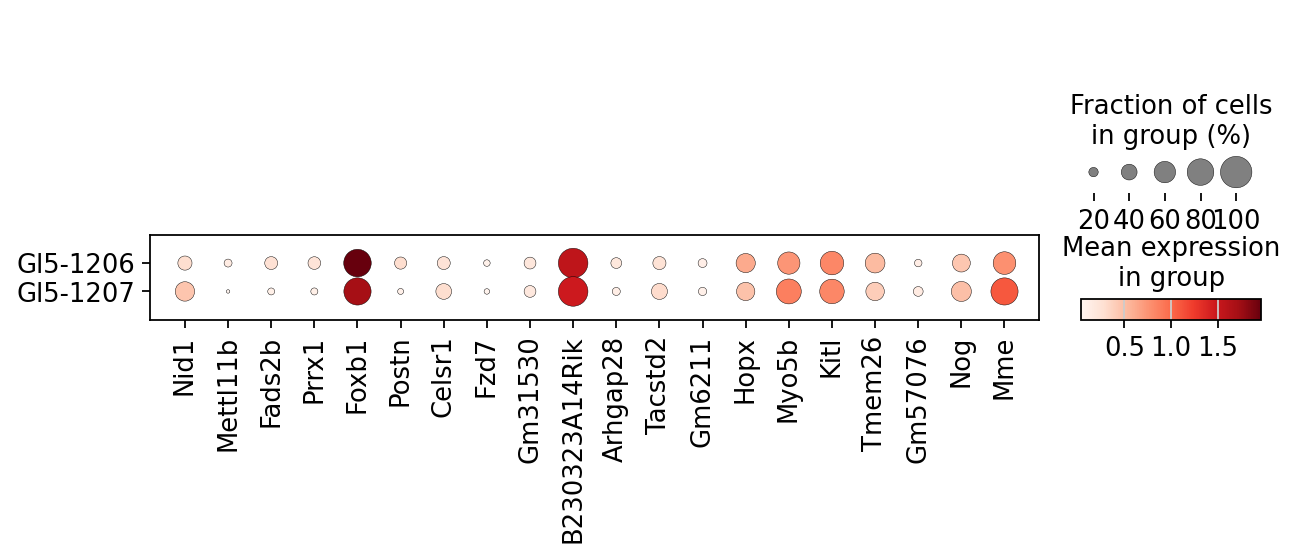

In [34]:
g = markers[(markers.cluster == "Gl5-1206") & (markers.comparison == "OneVsAll")].head(20).gene_name.to_list()
sc.pl.dotplot(adata[adata.obs["Is_Gl4-0629_top"]], var_names=g, groupby="L5")

On the other hand, the cells at the bottom are not Glutamatergic but GABA-ergic, suggesting that they were incorrectly assigned to the glutamatergic cell hierarchy.

/REDACTED-path/HypoMap3D/.venv/lib/python3.11/site-packages/anndata/_core/anndata.py:1208: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


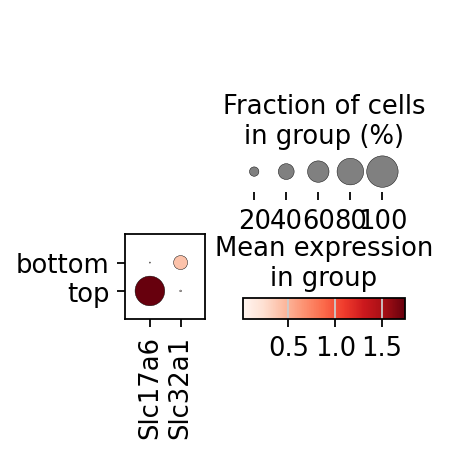

In [35]:
sc.pl.dotplot(adata[adata.obs.L4 == "Gl4-0629"], var_names=["Slc17a6","Slc32a1", ], groupby="Gl4-0629_part")

Furthermore, as the UMAP region in which those bottom cells are is dominated by clusters we previously mapped to the striatum it is likely that these cells are non-HY.

Hence, we decided to remove those bottom cells from the cluster

<Axes: title={'center': 'Is_Gl4-0629_bottom'}, xlabel='UMAP1', ylabel='UMAP2'>

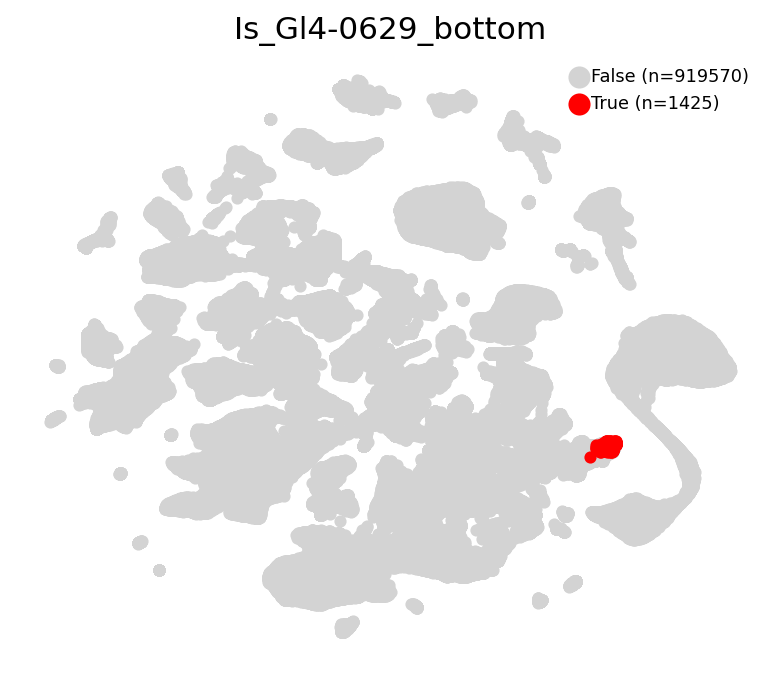

In [36]:
plot_umap_flag(adata, flag_col="Is_Gl4-0629_bottom", ax=None, true_color="red", false_color="lightgrey", s_false=20, s_true=20, title=None)

In [37]:
gl40629_to_remove = adata[adata.obs["Is_Gl4-0629_bottom"]].obs_names

### Let's collect all cells to be removed

In [38]:
adata.obs["to_be_removed"] = adata.obs.L4.isin(clusters_to_remove)
adata.obs.loc[gl40212_to_remove, "to_be_removed"] = True
adata.obs.loc[gl40216_to_remove, "to_be_removed"] = True
adata.obs.loc[gl40629_to_remove, "to_be_removed"] = True

<Axes: title={'center': 'to_be_removed'}, xlabel='UMAP1', ylabel='UMAP2'>

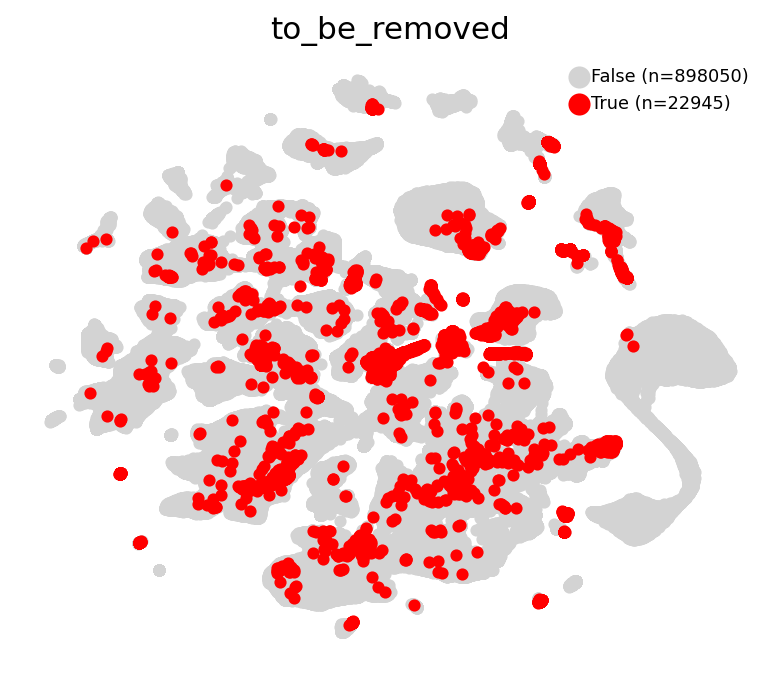

In [39]:
plot_umap_flag(adata, flag_col="to_be_removed", ax=None, true_color="red", false_color="lightgrey", s_false=20, s_true=20, title=None)

In [40]:
removed_cells = list(adata[adata.obs.to_be_removed].obs_names)

### Let's track what cells have been removed 

In [41]:
# Load existing file
qc_log_df = pd.read_csv(CELL_HISTORY)

qc_log_df["IsPosthocRemoved"] = False
qc_log_df.loc[qc_log_df.CellID.isin(removed_cells), "IsPosthocRemoved"] = True

# Atomically replace cell history to avoid data corruption
output_path = CELL_HISTORY
output_dir = output_path.parent
# Create temp file in same directory
with tempfile.NamedTemporaryFile(mode="w", delete=False, dir=output_dir, suffix=".csv") as tmp:
    temp_path = Path(tmp.name)
    qc_log_df.to_csv(tmp.name, index=False)

os.replace(temp_path, output_path)

### Let's remove the cells, tidy up the adata and save

In [8]:
adata = adata[~adata.obs.to_be_removed].copy()

In [ ]:
adata.X = adata.layers["raw"].copy()
del adata.layers["raw"], adata.uns["log1p"], adata.uns["L1_colors"]
adata.obs = adata.obs.drop(columns = ['Is_Gl4-0212', 'Is_Gl4-0212_to_remove', 'Is_Gl4-0216', 'Is_Gl4-0216_to_remove', 'Is_Gl4-0629', 
    'Is_Gl5-1207', 'Is_Gl5-1206', 'Is_Gl4-0629_top', 'Is_Gl4-0629_bottom', 'Gl4-0629_part'])

In [13]:
adata

AnnData object with n_obs × n_vars = 898050 × 56939
    obs: 'CellID', 'Dataset', 'Sample', 'total_counts', 'n_genes', 'pct_mito', 'Author', 'Source', 'Data_source_link', 'GEO', 'Publication_Link', 'Suspension', 'Technology', 'Author_Sex_harmonized', 'Strain', 'Diet', 'Treatment', 'Age', 'Mean_age_in_weeks', 'IsControl', 'cluster_id_label', 'supertype_id_label', 'subclass_id_label', 'class_id_label', 'C66_named', 'C185_named', 'C286_named', 'C465_named', 'ABC_class_propagated', 'ABC_class_confidence', 'to_be_removed', 'IsNeuronal', 'major_features', 'major_features_propagated', 'major_features_confidence', 'ABC_supertype_propagated', 'ABC_supertype_confidence', 'ABC_subclass_propagated', 'ABC_subclass_confidence', 'ABC_cluster_propagated', 'ABC_cluster_confidence', 'L1', 'L2', 'L3', 'L4', 'L5'
    var: 'gene_ids', 'IsMouseTF', 'IsHumanTFOrtholog', 'IsSourceGene', 'IsTargetGene', 'IsHvgExcludedGene', 'IsAnnotationExcludedGene', 'IsPriorityGene', 'IsTopGene', 'IsHvg'
    uns: 'neighbors'

In [14]:
with tracker.register(ADATA_OUT_FP) as tf:
    tf.set_description('Control Hypomap3D with low quality clusters/cells removed.')
    write_clean_h5ad(adata, tf.filepath)